In [ ]:
import pandas as pd
df = pd.read_csv('../content/spam.csv', encoding='latin-1')
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
df = df.rename(columns={'v1': 'label', 'v2': 'message'})
df.head()

,label,message,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
columns_to_drop = [col for col in df.columns if 'Unnamed' in col]
df = df.drop(columns=columns_to_drop)
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['label'] = le.fit_transform(df['label'])
df.head()

,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
df.isnull().sum()

,0
label,0
message,0


In [ ]:
df.drop_duplicates(keep="first", inplace=True)
df.duplicated().sum()

np.int64(0)

In [ ]:
df['label'].value_counts(normalize=True)

,proportion
label,
0,0.87367
1,0.12633


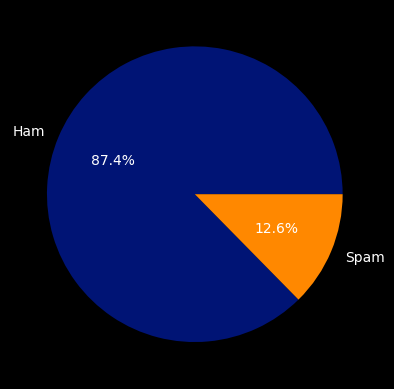

In [ ]:
from matplotlib import pyplot as plt

my_colors = ['#001475', '#FF8800']
plt.pie(df['label'].value_counts(normalize=True), labels=["Ham", "Spam"], colors=my_colors, autopct="%1.1f%%")
plt.show()

In [ ]:
import re
from bs4 import BeautifulSoup

def preprocess_text(text):
    """
    Preprocessing rules:
    - Remove HTML & headers
    - Normalize whitespace
    - Lowercase text
    - Replace URLs and emails with tokens
    - Keep punctuation signals (! ? $)
    """

    if not isinstance(text, str):
        return ""

    # 1. Remove HTML tags
    text = BeautifulSoup(text, "html.parser").get_text()

    # 2. Remove common email headers
    text = re.sub(r'(subject|from|to|date):', ' ', text, flags=re.IGNORECASE)

    # 3. Replace URLs with token
    text = re.sub(r'(http\S+|www\S+)', ' URL ', text)

    # 4. Replace email addresses with token
    text = re.sub(r'\S+@\S+', ' EMAIL ', text)

    # 5. Lowercase
    text = text.lower()

    # 6. Keep punctuation signals, remove other junk
    text = re.sub(r'[^a-z0-9!?$]', ' ', text)

    # 7. Normalize whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text


In [ ]:
df["message_length"] = df.apply(lambda x: len(x["message"]), axis=1)
df["clean_msg"] = df.apply(lambda x: preprocess_text(x["message"]), axis=1)
df["preprocess_length"] = df.apply(lambda x: len(x["clean_msg"]), axis=1)
df.head()

,label,message,message_length,clean_msg,preprocess_length
0,0,"Go until jurong point, crazy.. Available only ...",111,go until jurong point crazy available only in ...,102
1,0,Ok lar... Joking wif u oni...,29,ok lar joking wif u oni,23
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,free entry in 2 a wkly comp to win fa cup fina...,154
3,0,U dun say so early hor... U c already then say...,49,u dun say so early hor u c already then say,43
4,0,"Nah I don't think he goes to usf, he lives aro...",61,nah i don t think he goes to usf he lives arou...,60


In [ ]:
from sklearn.model_selection import train_test_split

X = df['clean_msg']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    analyzer='word',
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(class_weight={0:1, 1:2},max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(class_weight={0: 1, 1: 2}, max_iter=1000)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

def evaluate_model(model, X_test, y_test):
    y_prob = model.predict_proba(X_test)[:, 1]
    threshold = 0.27
    y_pred_final = (y_prob >= threshold).astype(int)

    print(f"Confusion Matrix (Threshold = {threshold})")
    print(confusion_matrix(y_test, y_pred_final))

    print(f"\nClassification Report (Threshold = {threshold})")
    print(classification_report(y_test, y_pred_final, target_names=["Ham", "Spam"]))

In [ ]:
evaluate_model(lr_model, X_test_tfidf, y_test)

Confusion Matrix (Threshold = 0.27)
[[894   9]
 [ 12 119]]

Classification Report (Threshold = 0.27)
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       903
        Spam       0.93      0.91      0.92       131

    accuracy                           0.98      1034
   macro avg       0.96      0.95      0.95      1034
weighted avg       0.98      0.98      0.98      1034



In [ ]:
y_prob = lr_model.predict_proba(X_test_tfidf)[:, 1]
threshold = 0.25
y_pred_final = (y_prob >= threshold).astype(int)

test_df = pd.DataFrame({
    "text": X_test.values,
    "true_label": y_test.values,
    "pred_label": y_pred_final
})

false_negatives = test_df[
    (test_df.true_label == 1) & (test_df.pred_label == 0)
]

false_positives = test_df[
    (test_df.true_label == 0) & (test_df.pred_label == 1)
]

In [ ]:
false_negatives.sample(5)["text"]

,text
329,sms ac sun0819 posts hello you seem cool
95,want explicit sex in 30 secs? ring 02073162414...
690,latest news! police station toilet stolen cops...
437,babe u want me dont u baby! im nasty and have ...
826,ringtoneking 84484


In [ ]:
false_positives.sample(5)["text"]

,text
827,nokia phone is lovly
277,ok ur typical reply
1003,aldrine rakhesh ex rtm here pls call urgent
739,hey great deal farm tour 9am to 5pm $95 pax $5...
327,k k sms chat with me


In [ ]:
"""
Confusion Matrix (Threshold = 0.3)
[[899   4]
 [ 20 111]]

Classification Report (Threshold = 0.3)
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       903
        Spam       0.97      0.85      0.90       131

    accuracy                           0.98      1034
   macro avg       0.97      0.92      0.94      1034
weighted avg       0.98      0.98      0.98      1034
"""

'\nConfusion Matrix (Threshold = 0.3)\n[[899   4]\n [ 20 111]]\n\nClassification Report (Threshold = 0.3)\n              precision    recall  f1-score   support\n\n         Ham       0.98      1.00      0.99       903\n        Spam       0.97      0.85      0.90       131\n\n    accuracy                           0.98      1034\n   macro avg       0.97      0.92      0.94      1034\nweighted avg       0.98      0.98      0.98      1034\n'

In [ ]:
feature_names = tfidf.get_feature_names_out()
coefficients = lr_model.coef_[0]

In [ ]:
top_spam_indices = np.argsort(coefficients)[-20:]
top_spam_words = [(feature_names[i], coefficients[i]) for i in top_spam_indices]

top_spam_words

[('uk', np.float64(2.140139270324078)),
 ('win', np.float64(2.245687455538918)),
 ('prize', np.float64(2.2552715455163774)),
 ('now', np.float64(2.2786774204118965)),
 ('150p', np.float64(2.3149875407852853)),
 ('chat', np.float64(2.332152879506601)),
 ('50', np.float64(2.4182311434484074)),
 ('for', np.float64(2.4226514017624927)),
 ('from', np.float64(2.4598936201906834)),
 ('claim', np.float64(2.8079805411672174)),
 ('your', np.float64(2.9501912317628527)),
 ('stop', np.float64(3.10072860296332)),
 ('to', np.float64(3.192492496189125)),
 ('mobile', np.float64(3.3085289330694176)),
 ('reply', np.float64(3.6401401886762743)),
 ('free', np.float64(3.7994350482770374)),
 ('text', np.float64(3.8197466446424153)),
 ('url', np.float64(4.431298682647586)),
 ('txt', np.float64(4.477765019323474)),
 ('call', np.float64(5.419739048880481))]

In [ ]:
top_ham_indices = np.argsort(coefficients)[:20]
top_ham_words = [(feature_names[i], coefficients[i]) for i in top_ham_indices]

top_ham_words

[('my', np.float64(-2.358506967553195)),
 ('me', np.float64(-2.075942104497875)),
 ('that', np.float64(-1.8651480818577342)),
 ('ok', np.float64(-1.6379993154742005)),
 ('it', np.float64(-1.537242244770545)),
 ('at', np.float64(-1.5188654956029681)),
 ('but', np.float64(-1.4579658220289158)),
 ('how', np.float64(-1.454748475427283)),
 ('what', np.float64(-1.3265625502698573)),
 ('come', np.float64(-1.3186776112757508)),
 ('he', np.float64(-1.310071733816811)),
 ('in', np.float64(-1.2668616509386943)),
 ('home', np.float64(-1.261017305320556)),
 ('da', np.float64(-1.2603379214154906)),
 ('so', np.float64(-1.2427176714038337)),
 ('its', np.float64(-1.20916226903617)),
 ('ll', np.float64(-1.1993916319883464)),
 ('got', np.float64(-1.1920642530595356)),
 ('going', np.float64(-1.1851983725088897)),
 ('then', np.float64(-1.1700881039666846))]

In [ ]:
"""
Naive Bayes - Confusion Matrix
[[903   0]
 [ 40  91]]

Naive Bayes - Classification Report
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       1.00      0.69      0.82       131

    accuracy                           0.96      1034
   macro avg       0.98      0.85      0.90      1034
weighted avg       0.96      0.96      0.96      1034


Logistic Regression - Confusion Matrix
[[902   1]
 [ 39  92]]

Logistic Regression - Classification Report
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       0.99      0.70      0.82       131

    accuracy                           0.96      1034
   macro avg       0.97      0.85      0.90      1034
weighted avg       0.96      0.96      0.96      1034
"""

'\nNaive Bayes - Confusion Matrix\n[[903   0]\n [ 40  91]]\n\nNaive Bayes - Classification Report\n              precision    recall  f1-score   support\n\n         Ham       0.96      1.00      0.98       903\n        Spam       1.00      0.69      0.82       131\n\n    accuracy                           0.96      1034\n   macro avg       0.98      0.85      0.90      1034\nweighted avg       0.96      0.96      0.96      1034\n\n\nLogistic Regression - Confusion Matrix\n[[902   1]\n [ 39  92]]\n\nLogistic Regression - Classification Report\n              precision    recall  f1-score   support\n\n         Ham       0.96      1.00      0.98       903\n        Spam       0.99      0.70      0.82       131\n\n    accuracy                           0.96      1034\n   macro avg       0.97      0.85      0.90      1034\nweighted avg       0.96      0.96      0.96      1034\n'